In [1]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Load Data
df = pd.read_csv('ai4i2020.csv')

# 2. Physics-Informed Feature Engineering
# Explicitly capture the deterministic relationships that govern AI4I failure modes
df['Temp_Difference'] = df['Process temperature [K]'] - df['Air temperature [K]']
df['Power_Watts'] = df['Torque [Nm]'] * (df['Rotational speed [rpm]'] * (2 * np.pi / 60))
df['Overstrain'] = df['Tool wear [min]'] * df['Torque [Nm]']

# 3. Ground Truth & Feature Separation
# Use canonical 'Machine failure' to prevent mismatch issues with raw failure modes
y = df['Machine failure']
X = df.drop(columns=['UDI', 'Product ID', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF'])

# 4. Train-Test Split (Split first to prevent data leakage during scaling/encoding)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=52, stratify=y
)

# 5. Targeted Feature Preprocessing
categorical_cols = ['Type']
numeric_cols = [col for col in X.columns if col not in categorical_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_cols)
    ]
)

# Fit exclusively on the training set, transform both
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

# 6. Compute Positive Class Weight Ratio for GBDTs
# Pass this directly to scale_pos_weight in XGBoost / LightGBM
weight_ratio = (y_train == 0).sum() / (y_train == 1).sum()

print("Preprocessing complete (without SMOTE).")
print(f"X_train shape: {X_train_proc.shape}, X_test shape: {X_test_proc.shape}")
print(f"Positive-to-negative weight ratio for GBDT: {weight_ratio:.2f}")

Preprocessing complete (without SMOTE).
X_train shape: (8500, 10), X_test shape: (1500, 10)
Positive-to-negative weight ratio for GBDT: 28.51


In [2]:
import numpy as np
import optuna
from sklearn.metrics import classification_report, f1_score, precision_recall_curve
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

# Suppress verbose Optuna trial logs to keep terminal output clean
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ==============================================================================
# 1. OPTUNA OBJECTIVE FUNCTION (BAYESIAN SEARCH)
# ==============================================================================
def objective(trial):
    """
    Evaluates a single hyperparameter configuration suggested by Optuna's
    Tree-structured Parzen Estimator (TPE) using 5-Fold Stratified Cross-Validation.
    """
    params = {
        # GPU acceleration configuration for RTX 4050
        "device": "cuda",
        "tree_method": "hist",
        "eval_metric": "logloss",
        "random_state": 52,
        # Tree depth and sample weight constraints
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 8),
        # Boosting iterations & step shrinkage
        "n_estimators": trial.suggest_int("n_estimators", 150, 600),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        # Stochastic feature and row subsampling to prevent overfitting
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        # Regularization parameters
        "gamma": trial.suggest_float("gamma", 0.0, 3.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1.0, 10.0),
        # Cost-sensitive weighting centered around our empirical ratio (~28.51)
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 10.0, 35.0),
    }

    # 5-fold cross-validation preserves minority failure class proportions
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=52)
    cv_f1_scores = []

    for train_idx, val_idx in cv.split(X_train_proc, y_train):
        X_fold_train, X_fold_val = X_train_proc[train_idx], X_train_proc[val_idx]
        y_fold_train, y_fold_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

        model = XGBClassifier(**params)
        model.fit(X_fold_train, y_fold_train, verbose=False)

        # Generate predicted probabilities for the positive failure class
        preds = model.predict(X_fold_val)
        cv_f1_scores.append(f1_score(y_fold_val, preds, zero_division=0))

    # Optuna maximizes the average validation F1-score across all 5 folds
    return np.mean(cv_f1_scores)


print("Launching Optuna Bayesian Optimization on RTX 4050...")
sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction="maximize", sampler=sampler)
study.optimize(objective, n_trials=60, show_progress_bar=True)

print(f"\nBest Cross-Validation F1-Score: {study.best_value:.4f}")
print("Optimal Parameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")


# ==============================================================================
# 2. OUT-OF-FOLD (OOF) PROBABILITY GENERATION FOR THRESHOLD TUNING
# ==============================================================================
# To find the best threshold without test-set leakage, gather predictions on
# validation folds using the best hyperparameters found by Optuna.

best_params = study.best_params.copy()
best_params.update(
    {
        "device": "cuda",
        "tree_method": "hist",
        "eval_metric": "logloss",
        "random_state": 52,
    }
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=52)
oof_probs = np.zeros(len(X_train_proc))

for train_idx, val_idx in cv.split(X_train_proc, y_train):
    X_fold_train, X_fold_val = X_train_proc[train_idx], X_train_proc[val_idx]
    y_fold_train = y_train.iloc[train_idx]

    fold_model = XGBClassifier(**best_params)
    fold_model.fit(X_fold_train, y_fold_train, verbose=False)

    # Save out-of-fold predicted probabilities for positive class (failure)
    oof_probs[val_idx] = fold_model.predict_proba(X_fold_val)[:, 1]

# Precision-Recall curve calculation across all unique probability cutoffs
precisions, recalls, thresholds = precision_recall_curve(y_train, oof_probs)

# Calculate F1 score for each threshold (excluding edge division errors)
f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[best_threshold_idx]

print(f"\nDefault Decision Threshold: 0.5000")
print(f"Empirically Tuned Decision Threshold: {optimal_threshold:.4f}")
print(f"Expected Peak F1 at this Threshold: {f1_scores[best_threshold_idx]:.4f}")


# ==============================================================================
# 3. FINAL RETRAINING AND UNBIASED TEST EVALUATION
# ==============================================================================
# Fit final model on the entire training set (8,500 samples)
final_model = XGBClassifier(**best_params)
final_model.fit(X_train_proc, y_train, verbose=False)

# Predict probabilities on the untouched holdout test set (1,500 samples)
test_probs = final_model.predict_proba(X_test_proc)[:, 1]

# Standard threshold (0.5) evaluation
test_preds_default = (test_probs >= 0.5).astype(int)

# Optimal threshold evaluation
test_preds_tuned = (test_probs >= optimal_threshold).astype(int)

print("\n" + "=" * 65)
print("TEST SET EVALUATION: DEFAULT THRESHOLD (0.50)")
print("=" * 65)
print(classification_report(y_test, test_preds_default, digits=4))

print("=" * 65)
print(f"TEST SET EVALUATION: OPTIMIZED THRESHOLD ({optimal_threshold:.4f})")
print("=" * 65)
print(classification_report(y_test, test_preds_tuned, digits=4))

d:\ML Codes\AI4I\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Launching Optuna Bayesian Optimization on RTX 4050...


  0%|          | 0/60 [00:00<?, ?it/s]d:\ML Codes\AI4I\venv\lib\site-packages\xgboost\core.py:751: UserWarning: [17:38:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\common\error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)
Best trial: 51. Best value: 0.800362: 100%|██████████| 60/60 [02:44<00:00,  2.74s/it]



Best Cross-Validation F1-Score: 0.8004
Optimal Parameters:
  max_depth: 9
  min_child_weight: 1
  n_estimators: 252
  learning_rate: 0.05748807707895322
  subsample: 0.8866065665302642
  colsample_bytree: 0.8500432762948557
  gamma: 1.8009033216030352
  reg_alpha: 0.002198986558572664
  reg_lambda: 3.471189832390576
  scale_pos_weight: 10.515371859277845

Default Decision Threshold: 0.5000
Empirically Tuned Decision Threshold: 0.7813
Expected Peak F1 at this Threshold: 0.8255

TEST SET EVALUATION: DEFAULT THRESHOLD (0.50)
              precision    recall  f1-score   support

           0     0.9958    0.9931    0.9945      1449
           1     0.8182    0.8824    0.8491        51

    accuracy                         0.9893      1500
   macro avg     0.9070    0.9377    0.9218      1500
weighted avg     0.9898    0.9893    0.9895      1500

TEST SET EVALUATION: OPTIMIZED THRESHOLD (0.7813)
              precision    recall  f1-score   support

           0     0.9952    0.9979    0.

In [3]:
import joblib
import numpy as np
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

# ======================================================================
# DETAILED UNSEEN TEST EVALUATION & SERIALIZATION
# ======================================================================

# 1. Compute overall ranking metrics (threshold-independent)
roc_auc = roc_auc_score(y_test, test_probs)
pr_auc = average_precision_score(y_test, test_probs)


def display_threshold_metrics(threshold_val, preds, title):
    rec = recall_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()

    print("=" * 65)
    print(f"{title} (Threshold = {threshold_val:.4f})")
    print("=" * 65)
    print(f"Recall:                 {rec:.4f}  ({tp}/{tp+fn} failures caught)")
    print(f"Precision:              {prec:.4f}")
    print(f"F1-Score:               {f1:.4f}")
    print(f"ROC-AUC:                {roc_auc:.4f}")
    print(f"PR-AUC (Avg Precision): {pr_auc:.4f}")
    print(f"Missed Failures (FN):   {fn}")
    print(f"False Alarms (FP):      {fp}")
    print("\nClassification Report:")
    print(
        classification_report(
            y_test, preds, target_names=["Healthy (0)", "Failure (1)"], digits=4
        )
    )


# Display comparative performance
display_threshold_metrics(
    0.50, test_preds_default, "XGBOOST PERFORMANCE: DEFAULT THRESHOLD"
)
display_threshold_metrics(
    optimal_threshold, test_preds_tuned, "XGBOOST PERFORMANCE: TUNED THRESHOLD"
)

# ======================================================================
# ARTIFACT SERIALIZATION FOR FASTAPI & STREAMLIT
# ======================================================================
# 1. Save the model alone (backward compatible with existing scripts)
joblib.dump(final_model, "tuned_xgboost_model.pkl")

# 2. Save the fitted preprocessor (required to scale/encode live streaming data)
joblib.dump(preprocessor, "preprocessor.pkl")

# 3. Save full production bundle containing weights and operational threshold
production_artifacts = {
    "model": final_model,
    "preprocessor": preprocessor,
    "optimal_threshold": float(optimal_threshold),
    "features": list(X.columns),
}
joblib.dump(production_artifacts, "predictive_maintenance_bundle.pkl")

print("\nSaved artifacts to disk:")
print("  - 'tuned_xgboost_model.pkl' (Trained Model)")
print("  - 'preprocessor.pkl' (Fitted ColumnTransformer)")
print("  - 'predictive_maintenance_bundle.pkl' (Full Pipeline Bundle)")

XGBOOST PERFORMANCE: DEFAULT THRESHOLD (Threshold = 0.5000)
Recall:                 0.8824  (45/51 failures caught)
Precision:              0.8182
F1-Score:               0.8491
ROC-AUC:                0.9866
PR-AUC (Avg Precision): 0.9130
Missed Failures (FN):   6
False Alarms (FP):      10

Classification Report:
              precision    recall  f1-score   support

 Healthy (0)     0.9958    0.9931    0.9945      1449
 Failure (1)     0.8182    0.8824    0.8491        51

    accuracy                         0.9893      1500
   macro avg     0.9070    0.9377    0.9218      1500
weighted avg     0.9898    0.9893    0.9895      1500

XGBOOST PERFORMANCE: TUNED THRESHOLD (Threshold = 0.7813)
Recall:                 0.8627  (44/51 failures caught)
Precision:              0.9362
F1-Score:               0.8980
ROC-AUC:                0.9866
PR-AUC (Avg Precision): 0.9130
Missed Failures (FN):   7
False Alarms (FP):      3

Classification Report:
              precision    recall  f1-scor

XGBOOST THRESHOLD OPTIMIZATION: RECALL vs. F1-SCORE TRADE-OFF
Threshold Recall (Catch Rate) Precision F1-Score  Caught Failures (TP)  Missed Failures (FN)  False Alarms (FP)
     0.05              0.9714    0.1659   0.2833                    68                     2                342
     0.10              0.9571    0.2233   0.3622                    67                     3                233
     0.15              0.9429    0.2651   0.4138                    66                     4                183
     0.20              0.9286    0.2941   0.4467                    65                     5                156
     0.25              0.9286    0.3250   0.4815                    65                     5                135
     0.30              0.9143    0.3516   0.5079                    64                     6                118
     0.35              0.9143    0.3879   0.5447                    64                     6                101
     0.40              0.9000    0.3987   

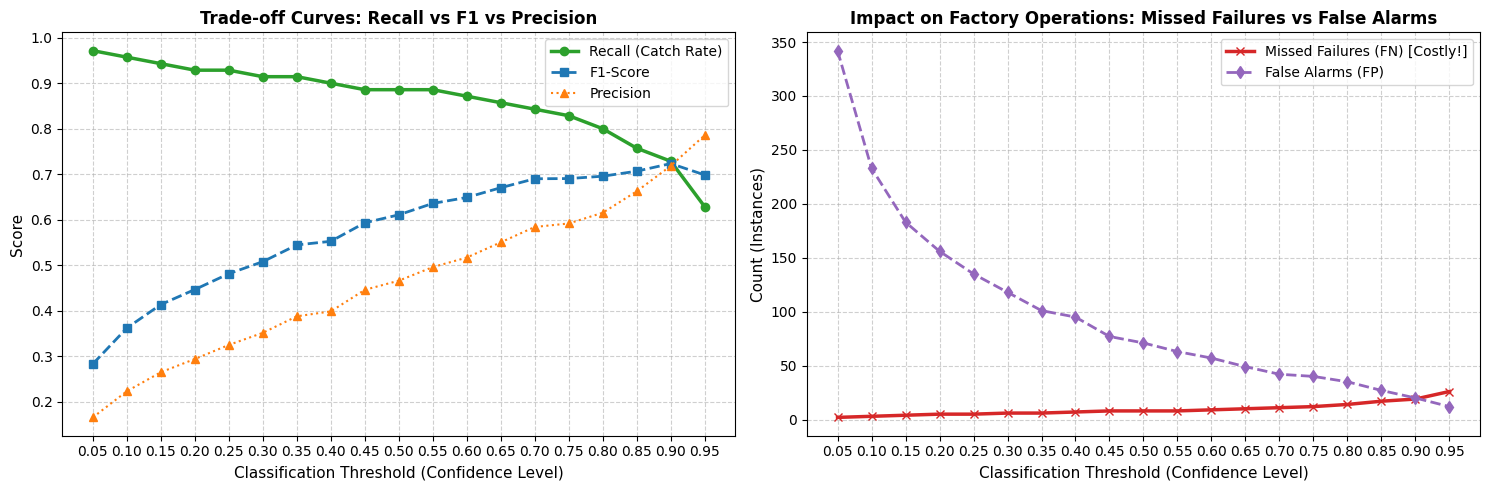

In [13]:
# ======================================================================
# CONFIDENCE LEVEL / THRESHOLD TUNING: MAXIMIZING RECALL FOR XGBOOST
# ======================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import recall_score, precision_score, f1_score, confusion_matrix

# Ensure y_proba and best_xgb are available
if 'y_proba' not in locals():
    if 'best_xgb' not in locals():
        import joblib
        best_xgb = joblib.load('tuned_xgboost_model.pkl')
    y_proba = best_xgb.predict_proba(X_test_scaled)[:, 1]

# Test fine-grained confidence thresholds from 0.05 to 0.50
thresholds = np.arange(0.05, 1, 0.05)

records = []
total_failures = int(y_test.sum())
total_healthy = int((y_test == 0).sum())

for th in thresholds:
    y_pred_th = (y_proba >= th).astype(int)
    
    rec = recall_score(y_test, y_pred_th)
    prec = precision_score(y_test, y_pred_th, zero_division=0)
    f1 = f1_score(y_test, y_pred_th, zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_th).ravel()
    
    records.append({
        'Threshold': round(th, 2),
        'Recall (Catch Rate)': rec,
        'Precision': prec,
        'F1-Score': f1,
        'Caught Failures (TP)': tp,
        'Missed Failures (FN)': fn,
        'False Alarms (FP)': fp
    })

df_thresholds = pd.DataFrame(records)

print("=" * 95)
print("XGBOOST THRESHOLD OPTIMIZATION: RECALL vs. F1-SCORE TRADE-OFF")
print("=" * 95)
print(df_thresholds.to_string(
    index=False,
    formatters={
        'Threshold': '{:.2f}'.format,
        'Recall (Catch Rate)': '{:.4f}'.format,
        'Precision': '{:.4f}'.format,
        'F1-Score': '{:.4f}'.format
    }
))

# Dual Plot: Metrics Curve & Missed Failures vs False Alarms
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Recall, Precision, and F1 Curves across thresholds
axes[0].plot(df_thresholds['Threshold'], df_thresholds['Recall (Catch Rate)'], marker='o', color='#2ca02c', linewidth=2.5, label='Recall (Catch Rate)')
axes[0].plot(df_thresholds['Threshold'], df_thresholds['F1-Score'], marker='s', color='#1f77b4', linewidth=2, linestyle='--', label='F1-Score')
axes[0].plot(df_thresholds['Threshold'], df_thresholds['Precision'], marker='^', color='#ff7f0e', linewidth=1.5, linestyle=':', label='Precision')
axes[0].set_title('Trade-off Curves: Recall vs F1 vs Precision', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Classification Threshold (Confidence Level)', fontsize=11)
axes[0].set_ylabel('Score', fontsize=11)
axes[0].set_xticks(df_thresholds['Threshold'])
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=10)

# 2. Missed Failures (FN) vs False Alarms (FP)
axes[1].plot(df_thresholds['Threshold'], df_thresholds['Missed Failures (FN)'], marker='x', color='#d62728', linewidth=2.5, label='Missed Failures (FN) [Costly!]')
axes[1].plot(df_thresholds['Threshold'], df_thresholds['False Alarms (FP)'], marker='d', color='#9467bd', linewidth=2, linestyle='--', label='False Alarms (FP)')
axes[1].set_title('Impact on Factory Operations: Missed Failures vs False Alarms', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Classification Threshold (Confidence Level)', fontsize=11)
axes[1].set_ylabel('Count (Instances)', fontsize=11)
axes[1].set_xticks(df_thresholds['Threshold'])
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()


In [4]:
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

# ==============================================================================
# 1. LOAD STAGE 1 ARTIFACTS AND PREPARE MULTI-CLASS FAILURE LABELS
# ==============================================================================
# Load saved production bundle from Stage 1 (model, preprocessor, and threshold)
stage1_bundle = joblib.load("predictive_maintenance_bundle.pkl")
stage1_model = stage1_bundle["model"]
preprocessor = stage1_bundle["preprocessor"]
optimal_threshold = stage1_bundle["optimal_threshold"]

failure_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]


def extract_failure_type(row):
    """Maps active failure flags to a single discrete failure class label."""
    for mode in failure_columns:
        if row[mode] == 1:
            return mode
    return "Other"  # Captures unlabelled/ambiguous machine failure instances


# Assign failure category to the full raw dataframe
df["Failure_Type"] = df.apply(extract_failure_type, axis=1)

# Isolate failure cases within the existing training indices
train_failure_mask = y_train == 1
X_train_fail = X_train_proc[train_failure_mask.values]
y_train_fail_raw = df.loc[y_train[train_failure_mask].index, "Failure_Type"]

# Encode failure types into consecutive integer labels (0 to K-1)
label_encoder = LabelEncoder()
y_train_fail_encoded = label_encoder.fit_transform(y_train_fail_raw)
class_names = list(label_encoder.classes_)

print(f"Training Stage 2 on {len(X_train_fail)} historical failure incidents.")
print(f"Identified Failure Classes: {class_names}")
print(
    f"Class distribution among failures:\n{pd.Series(y_train_fail_raw).value_counts()}\n"
)


# ==============================================================================
# 2. TRAIN GPU-ACCELERATED MULTI-CLASS XGBOOST (STAGE 2)
# ==============================================================================
# Compute sample weights to balance rare failure modes (like RNF/TWF vs HDF/PWF)
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight("balanced", y_train_fail_encoded)

stage2_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_names),
    device="cuda",
    tree_method="hist",
    n_estimators=300,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.5,
    random_state=42,
    eval_metric="mlogloss",
)

# 5-fold cross-validation on failure cases to ensure model generalization
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_macro_f1 = cross_val_score(
    stage2_model,
    X_train_fail,
    y_train_fail_encoded,
    cv=cv,
    scoring="f1_macro",
    params={"sample_weight": sample_weights},
)
print(f"5-Fold CV Macro F1-Score (Stage 2): {cv_macro_f1.mean():.4f}")

# Fit the final Stage 2 model on all training failure cases
stage2_model.fit(X_train_fail, y_train_fail_encoded, sample_weight=sample_weights)


# ==============================================================================
# 3. UNBIASED TEST EVALUATION: STANDALONE & TWO-STAGE CASCADE
# ==============================================================================
# Ground truth for test set failures
test_failure_mask = y_test == 1
X_test_fail = X_test_proc[test_failure_mask.values]
y_test_fail_raw = df.loc[y_test[test_failure_mask].index, "Failure_Type"]
y_test_fail_encoded = label_encoder.transform(y_test_fail_raw)

# A. Standalone Accuracy: If Stage 1 were 100% perfect, how well does Stage 2 diagnose?
y_test_fail_preds = stage2_model.predict(X_test_fail)

print("=" * 65)
print("STAGE 2 STANDALONE DIAGNOSIS (ON TRUE TEST FAILURES)")
print("=" * 65)
print(
    classification_report(
        y_test_fail_encoded,
        y_test_fail_preds,
        target_names=class_names,
        digits=4,
        zero_division=0,
    )
)

# B. End-to-End Hierarchical Inference: Stage 1 Gatekeeper -> Stage 2 Diagnoser
# Pass all 1,500 test records through Stage 1 using the tuned alert threshold
stage1_test_probs = stage1_model.predict_proba(X_test_proc)[:, 1]
predicted_failures_mask = stage1_test_probs >= optimal_threshold

print("=" * 65)
print("END-TO-END PIPELINE SIMULATION (STAGE 1 -> STAGE 2)")
print("=" * 65)
print(f"Total unseen test points: {len(X_test_proc)}")
print(
    f"Stage 1 flagged failures: {predicted_failures_mask.sum()} out of {y_test.sum()} actual failures."
)

if predicted_failures_mask.sum() > 0:
    # Filter incoming stream to flagged points and diagnose root cause
    flagged_features = X_test_proc[predicted_failures_mask]
    stage2_predictions = stage2_model.predict(flagged_features)
    stage2_probabilities = stage2_model.predict_proba(flagged_features)

    predicted_labels = label_encoder.inverse_transform(stage2_predictions)

    # Preview live alerts for the first 5 flagged machines
    print("\nSample Incoming Failure Alerts:")
    for i in range(min(5, len(predicted_labels))):
        confidence = stage2_probabilities[i, stage2_predictions[i]] * 100
        print(
            f"  - Machine Alert #{i+1}: Diagnosed Cause = {predicted_labels[i]} ({confidence:.1f}% confidence)"
        )


# ==============================================================================
# 4. SERIALIZE TWO-STAGE ARCHITECTURE FOR FASTAPI & STREAMLIT
# ==============================================================================
two_stage_bundle = {
    "stage1_model": stage1_model,
    "stage2_model": stage2_model,
    "stage1_threshold": optimal_threshold,
    "preprocessor": preprocessor,
    "label_encoder": label_encoder,
    "failure_classes": class_names,
    "feature_names": stage1_bundle["features"],
}

joblib.dump(two_stage_bundle, "two_stage_predictive_maintenance_bundle.pkl")
joblib.dump(stage2_model, "tuned_stage2_multiclass_xgb.pkl")
joblib.dump(label_encoder, "failure_label_encoder.pkl")

print(
    "\nSuccessfully bundled and saved hierarchical pipeline to 'two_stage_predictive_maintenance_bundle.pkl'!"
)

Training Stage 2 on 288 historical failure incidents.
Identified Failure Classes: ['HDF', 'OSF', 'Other', 'PWF', 'TWF']
Class distribution among failures:
Failure_Type
HDF      99
PWF      72
OSF      68
TWF      41
Other     8
Name: count, dtype: int64

5-Fold CV Macro F1-Score (Stage 2): 0.8563
STAGE 2 STANDALONE DIAGNOSIS (ON TRUE TEST FAILURES)
              precision    recall  f1-score   support

         HDF     1.0000    1.0000    1.0000        16
         OSF     1.0000    0.9000    0.9474        10
       Other     1.0000    1.0000    1.0000         1
         PWF     1.0000    1.0000    1.0000        19
         TWF     0.8333    1.0000    0.9091         5

    accuracy                         0.9804        51
   macro avg     0.9667    0.9800    0.9713        51
weighted avg     0.9837    0.9804    0.9808        51

END-TO-END PIPELINE SIMULATION (STAGE 1 -> STAGE 2)
Total unseen test points: 1500
Stage 1 flagged failures: 47 out of 51 actual failures.

Sample Incoming Fail